Shape: (7857424, 8)

First 5 rows:
          PIT_ID        DATE       P_ID  LMS_ITEM_ID  \
0  PIT0009356404  2024-01-04  P00013902   2206942531   
1  PIT0009356406  2024-03-06  P00015594   1951450793   
2  PIT0009356410  2024-04-10  P00011450   2253629406   
3  PIT0009356412  2024-02-05  P00009749   2194972069   
4  PIT0009356415  2024-04-24  P00005991   2108868819   

                  TIMESTAMP   LOGIN_ID  INTERACTION_COUNT  \
0  2024-01-04T15:45:27.722Z  L00537558                  2   
1  2024-03-06T14:55:04.942Z  L02125951                  2   
2  2024-04-10T14:09:48.805Z  L01525121                  8   
3  2024-02-05T16:49:26.631Z  L01122786                  1   
4  2024-04-24T10:41:47.231Z  L01406156                  4   

   TOTAL_SECONDS_BEFORE_NEXT_INTERACTION  
0                                      3  
1                                     14  
2                                   1489  
3                                      3  
4                                     10  

Co

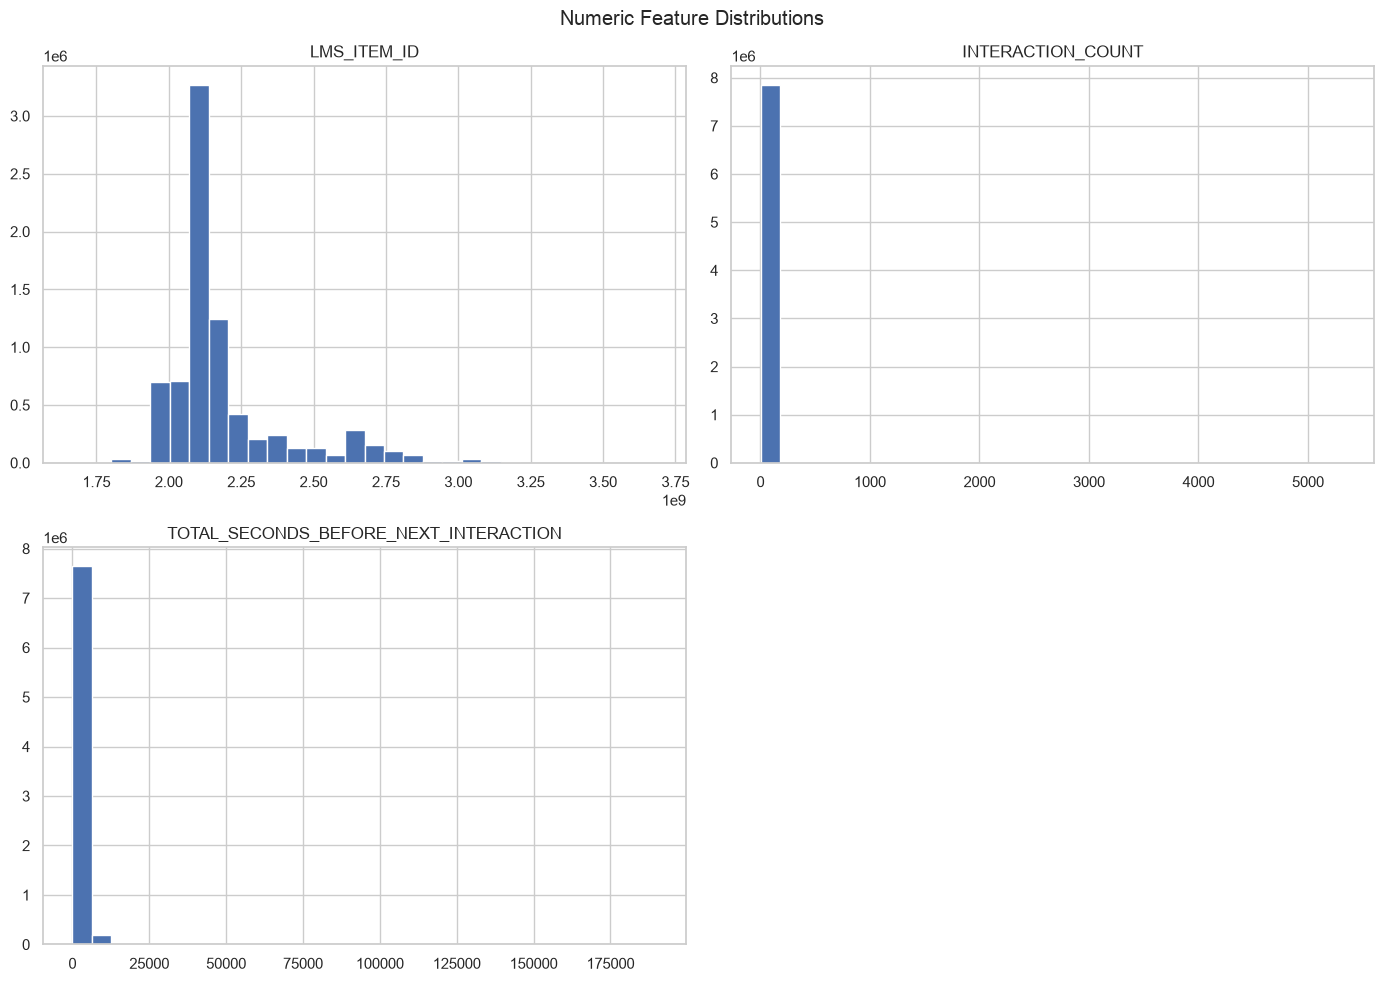

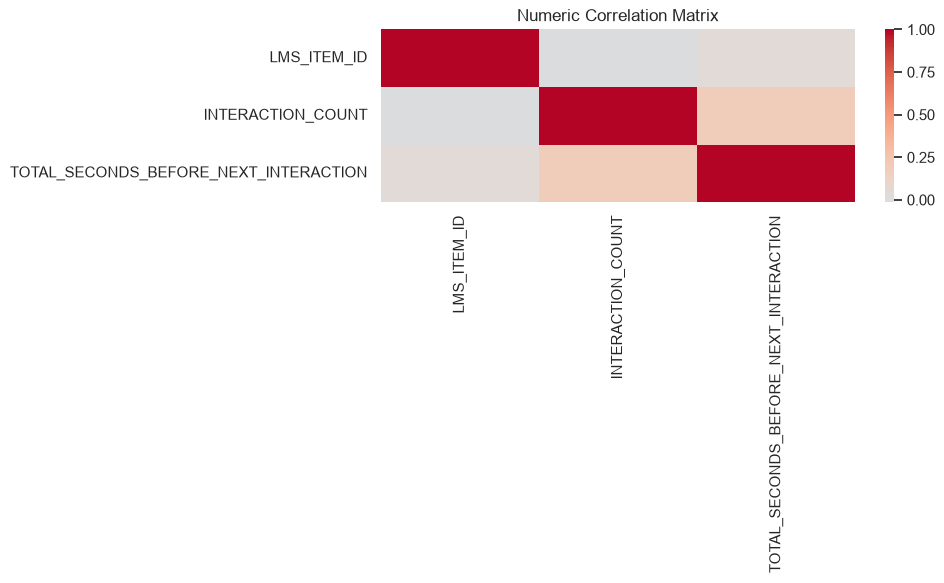


Top values for PIT_ID:
PIT_ID
PIT0014282623    2
PIT0004819282    2
PIT0004818814    2
PIT0004818437    2
PIT0004817885    2
PIT0004817598    2
PIT0004816918    2
PIT0004816589    2
PIT0004816335    2
PIT0004816217    2
Name: count, dtype: int64

Top values for DATE:
DATE
2023-10-09    60418
2023-11-13    57048
2023-10-16    56559
2023-10-30    55665
2023-10-23    54713
2023-11-06    54402
2023-11-20    54122
2023-10-10    53032
2023-10-12    51931
2023-11-27    50502
Name: count, dtype: int64

Top values for P_ID:
P_ID
P00006867    5915
P00016824    5818
P00002809    5341
P00009555    5289
P00013390    5208
P00000693    5036
P00018837    4806
P00008256    4785
P00020720    4770
P00008846    4718
Name: count, dtype: int64

Top values for TIMESTAMP:
TIMESTAMP
2024-08-30T07:29:11.076Z    15
2024-08-30T07:29:11.077Z    12
2024-09-24T21:49:26.800Z    12
2024-08-01T15:33:42.845Z    11
2024-08-10T02:06:06.628Z    10
2024-08-12T20:58:17.960Z    10
2024-09-27T08:22:03.640Z    10
2024-08-05T00

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

a = 1 
file_path = "Dataset/training/la_mmh_training_lms_item_activity_by_session_fact.csv"
df = pd.read_csv(file_path)

# Basic overview
print("Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)

# Missing values and duplicates
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_summary = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
print("\nMissing values:")
print(missing_summary[missing_summary["missing_count"] > 0])
print("\nDuplicate rows:", df.duplicated().sum())

# Summary statistics
print("\nNumeric summary:")
print(df.describe(include=[np.number]).T)

print("\nCategorical summary:")
cat_cols = df.select_dtypes(include=["object", "category", "bool"]).columns
if len(cat_cols) > 0:
    print(df[cat_cols].describe().T)
else:
    print("No categorical columns found.")

# Cardinality
print("\nUnique values per column:")
print(df.nunique().sort_values(ascending=False))

# Visual EDA
sns.set_theme(style="whitegrid")

numeric_cols = df.select_dtypes(include=np.number).columns
if len(numeric_cols) > 0:
    df[numeric_cols].hist(figsize=(14, 10), bins=30)
    plt.suptitle("Numeric Feature Distributions")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 6))
    sns.heatmap(df[numeric_cols].corr(), cmap="coolwarm", center=0)
    plt.title("Numeric Correlation Matrix")
    plt.tight_layout()
    plt.show()

# Top values for categorical columns
for col in cat_cols[:5]:
    print(f"\nTop values for {col}:")
    print(df[col].value_counts(dropna=False).head(10))
